---
---
# SIMPLE LINEAR REGRESSION

---
---

## ROADMAP: where we've been, and where we're going

* We've now began studying **predictive modeling**. When the response variable is *numeric*, we call this **regression** (numeric prediction).

* We introduced the first, and simplist, method: **k-nearest neighbours (k-NN)**. To predict the response for a new unit, average the responses of the $k$ units with the most similar explanatory variable values. And we learned the `scikit-learn` recipe: **create $\rightarrow$ fit $\rightarrow$ predict**.

* We learned to measure prediction error using **residuals** $r_i = y_i - \hat{y}_i$, and to summarize them with the **mean squared residual (MSR)** or the **mean absolute residual (MAR)**.

* We saw that k-NN has limitations: it depends heavily on $k$, it can't go beyond the values it has seen, and it doesn't give us a *summary* of the relationship such as *"how fast is the planet warming?"*

* We ended by noticing that the global temperature anomaly data looks *roughly like a straight line*, and wondering: **if we assume the pattern is a line, how do we find the best one?**

**Here we answer that question.** This is **simple linear regression**: predicting a numeric response using a *straight line* that depends on a *single* explanatory variable.

---
---

## Recap: The Global Temperature Anomaly Data

We continue with the NASA GISTEMP data. Recall that `Temp_Anomaly` is the global temperature *anomaly*: the difference (in $^\circ$C) between a year's global average temperature and the 1951-1980 average. We load it below.

In [33]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [36]:
temps = pd.read_csv('https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/global_temperature_change.csv')
temps["Year"] = temps["Year"].astype(int)

X = temps[["Year"]]          # explanatory variable (a data frame)
y = temps["Temp_Anomaly"]    # response variable (a series)

temps

,Year,Temp_Anomaly
0,1880,-0.172500
1,1881,-0.087500
2,1882,-0.111667
3,1883,-0.175833
4,1884,-0.282500
...,...,...
141,2021,0.847500
142,2022,0.890000
143,2023,1.167500
144,2024,1.281667


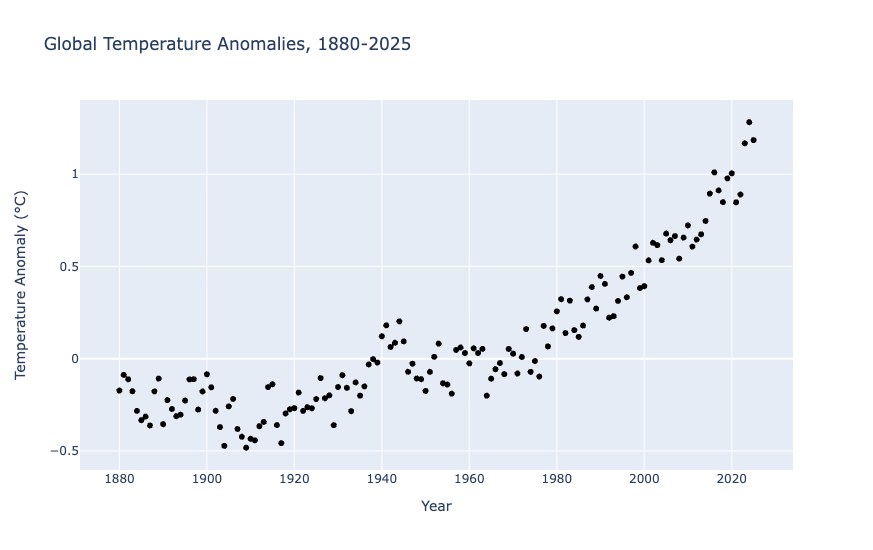

In [37]:
fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Global Temperature Anomalies, 1880-2025",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)
fig.show()

---
---

## The Line of Best Fit

### What is a line?

Recall from high school that a straight line can be written as:

$$\hat{y} = b_0 + b_1 x$$

where

* $x$ is the explanatory variable (here, `Year`),
* $\hat{y}$ is the line's **prediction** for the response at that value of $x$,
* $b_0$ is the **intercept**: the height of the line when $x = 0$, and
* $b_1$ is the **slope**: how much the line rises (or falls) for each one-unit increase in $x$.

The intercept $b_0$ and the slope $b_1$ are called the model's **coefficients** (or *parameters*). Once we've chosen values for them, we've chosen a line. **Different coefficients give different lines.**

### Many lines, which is best?

Below are three lines drawn through the temperature data. Each line is defined by two points it passes through.

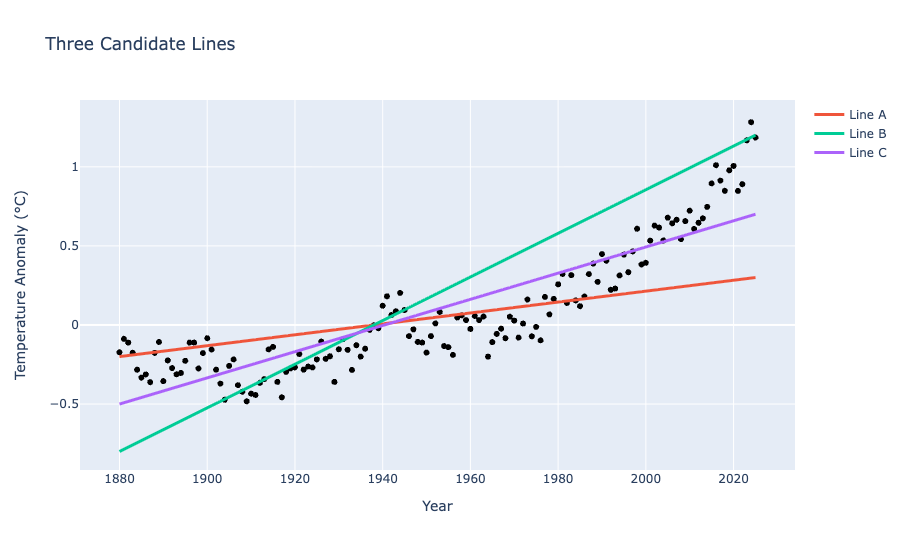

In [7]:
# Each candidate line passes through two points: (1880, anomaly_1880) and (2025, anomaly_2025)
candidates = {"Line A": (-0.20, 0.30),
              "Line B": (-0.80, 1.20),
              "Line C": (-0.50, 0.70)}

fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Three Candidate Lines",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)

for name, (start, end) in candidates.items():
    fig.add_scatter(x = [1880, 2025], y = [start, end], mode = "lines", name = name, line = dict(width = 3))

fig.data[0].name = "Observed data"
fig.update_layout(showlegend = True)

Which of these lines fits the data best? Your eyes might say Line C. But we want a *precise*, *objective* way of deciding, one that a computer can carry out. We already have the tool: **residuals!**

For each candidate line we can compute the slope and intercept from the two points it passes through, make a prediction $\hat{y}_i$ for every year, and then compute the residuals and their MSR and MAR, exactly as we did last lecture.

In [38]:
rows = []
for name, (start, end) in candidates.items():
    slope = (end - start) / (2025 - 1880)       # rise over run
    intercept = start - slope * 1880            # height of the line at Year = 0
    predictions = intercept + slope * temps["Year"]
    residuals = temps["Temp_Anomaly"] - predictions
    rows.append({"Line": name,
                 "Slope": slope,
                 "Intercept": intercept,
                 "MSR": (residuals ** 2).mean(),
                 "MAR": residuals.abs().mean()})

pd.DataFrame(rows)

,Line,Slope,Intercept,MSR,MAR
0,Line A,0.003448,-6.682759,0.079592,0.208523
1,Line B,0.013793,-26.731034,0.105273,0.273228
2,Line C,0.008276,-16.058621,0.037600,0.159029


Line C has by far the smallest MSR and MAR, confirming what our eyes told us. Lines A and B both miss the data by large amounts: A is too flat and B is too steep.

**So here's the idea.** Out of the *infinitely many* possible lines, define the **line of best fit** as the one whose residuals are smallest overall.

---
---

## Estimation as Optimization: The Objective (Loss) Function

### Loss Functions

Notice the strategy we just used:

1. Choose a way to **measure** how badly a line fits the data. This measure is called an **objective function**. In the field of machine learning, objective functions are referred to as **loss functions**. We will use that terminology here.
2. A loss function is *large* for bad lines and *small* for good lines.
3. Find the line (the coefficients $b_0$ and $b_1$) that makes the loss as **small as possible**.

This strategy, **estimating parameters by optimizing an objective function**, is the engine inside almost every machine learning method. It is *not* special to lines. In the lectures ahead, even for very different models, the story will be the same: *pick a loss, then find the parameter values that minimize it.*

We already have two loss functions from last lecture:

| Name | Loss function | In words |
|---|---|---|
| **Least squares** | $\displaystyle \text{SSR}(b_0, b_1) = \sum_{i=1}^{n} \left(y_i - (b_0 + b_1 x_i)\right)^2$ | Find the line with the smallest **sum of squared residuals**. |
| **Least absolute error** | $\displaystyle \text{SAR}(b_0, b_1) = \sum_{i=1}^{n} \lvert y_i - (b_0 + b_1 x_i) \rvert$ | Find the line with the smallest **sum of absolute residuals**. |

Notice that we've written the losses as functions of $b_0$ and $b_1$. The data ($x_i$ and $y_i$) are *fixed*; the coefficients are what we get to *vary*. Every pair $(b_0, b_1)$ yields a different line and therefore a different loss.

### Finding the best line by brute force

How might a computer find the coefficients that minimize the loss function? The most straightforward approach is **brute force**:

> Try *lots* of different values of $b_0$ and $b_1$. For each pair, compute the value of the loss function. Keep the pair with the smallest loss.

To keep the search simple, we'll measure time as **years from the middle of the data** (the average year, 1952.5) rather than as the raw year. (We'll see *why* this is a smart choice shortly.)

In [39]:
temps["Year_centered"] = temps["Year"] - temps["Year"].mean()
temps[["Year", "Year_centered", "Temp_Anomaly"]].head()

,Year,Year_centered,Temp_Anomaly
0,1880,-72.5,-0.172500
1,1881,-71.5,-0.087500
2,1882,-70.5,-0.111667
3,1883,-69.5,-0.175833
4,1884,-68.5,-0.282500


In [40]:
# Brute force: try many intercepts and slopes, and record the SSR and SAR of each
x = temps["Year_centered"]

search = []
for b0 in np.arange(-0.20, 0.401, 0.01):          # candidate intercepts
    for b1 in np.arange(0, 0.0201, 0.00025):      # candidate slopes
        residuals = y - (b0 + b1 * x)
        search.append({"b0": b0, "b1": b1,
                       "SSR": (residuals ** 2).sum(),
                       "SAR": residuals.abs().sum()})

search = pd.DataFrame(search)
search.shape

(4941, 4)

We tried nearly 5000 different lines! Which gave the smallest SSR?

In [41]:
search.sort_values(by = "SSR").head()

,b0,b1,SSR,SAR
2301,0.08,0.00825,5.450595,22.938166
2382,0.09,0.00825,5.455462,23.021333
2302,0.08,0.00850,5.465244,22.943833
2300,0.08,0.00800,5.468362,22.962666
2383,0.09,0.00850,5.470111,23.080333


And which gave the smallest SAR?

In [42]:
search.sort_values(by = "SAR").head()

,b0,b1,SSR,SAR
2059,0.05,0.00850,5.625844,22.868833
2060,0.05,0.00875,5.672910,22.872916
2140,0.06,0.00850,5.543111,22.877333
2141,0.06,0.00875,5.590177,22.879167
1978,0.04,0.00850,5.737778,22.888666


Two important observations:

* The **loss surface** has a single "valley" (see below). Moving away from the best $(b_0, b_1)$ in *any* direction makes the loss larger.
* **Different loss functions give (slightly) different best lines.** The least squares line and the least absolute error line are close, but not identical.

Let's visualize the loss over every pair of $(b_0, b_1)$ that we tried. Each dot is a different line, coloured by its SSR. The bright region at the centre is the valley where the SSR is smallest.

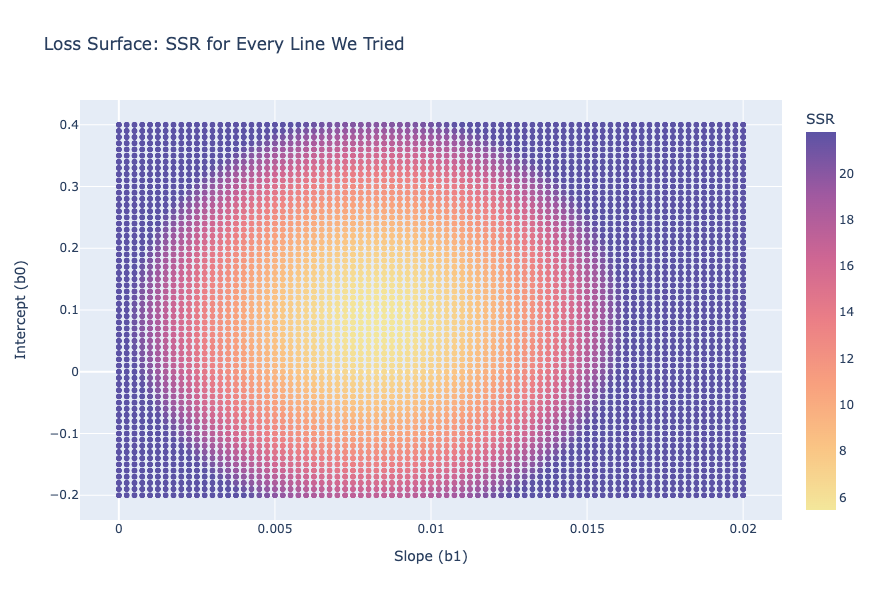

In [47]:
fig = px.scatter(search, x = "b1", y = "b0", color = "SSR",
                 title = "Loss Surface: SSR for Every Line We Tried",
                 labels = {"b1": "Slope (b1)", "b0": "Intercept (b0)"},
                 color_continuous_scale = "sunset",
                 range_color = [search["SSR"].min(), 4 * search["SSR"].min()],
                 height = 600)
fig

This search is slow and crude: we only checked values on a grid, and we had to *guess* where to look. Real software doesn't do this. It uses clever mathematical shortcuts (calculus and optimization algorithms) to find the minimum directly. But the *idea* is the same as what we just did: **estimation means finding the parameter values that minimize the loss function.**

---
---

## 💻 Interactive: Build Your Intuition for Optimization

Let's play with the idea of fitting a line by optimizing an objective function (i.e., minimizing a loss function). Use the app below to explore how the choice of line changes the loss, and what it means to find the line that makes the loss as small as possible.

> **If the app doesn't display below**, open it in its own browser tab: [https://nathaniel-t-stevens.shinyapps.io/linear_regression_app/](https://nathaniel-t-stevens.shinyapps.io/linear_regression_app/)

In [48]:
%%html
<div style="text-align: center;">
<iframe src="https://nathaniel-t-stevens.shinyapps.io/linear_regression_app/" width="100%" height="850" frameborder="0"></iframe>
</div>

**Explore the app, then discuss with your neighbours:**

1. Try to *find the best line by hand*. Adjust the line and watch the loss. What makes the loss *larger*? What makes it *smaller*?
2. How do you know when you've found the best line? What would you see if you moved the line a little bit in *any* direction?
3. Compare **least squares** and **least absolute error**. Do they give the same line? When might they differ?

**Key idea:** the "best" line isn't a matter of opinion. Once we pick a loss function, the best line is the one with the smallest loss. A computer can find it for us.

---
---

## Linear Regression with `scikit-learn`

Now let's let `scikit-learn` do the optimization for us. We follow the same recipe as with $k$ nearest neightbours: **create $\rightarrow$ fit $\rightarrow$ predict**. The only thing that changes is the model we create. The method that finds the **least squares** line is called `LinearRegression`.

In [15]:
from sklearn.linear_model import LinearRegression

# 1. Create the model
lin = LinearRegression()

# 2. Fit the model (this is where the optimization happens!)
lin.fit(X, y)

LinearRegression()

After fitting, the model stores the optimized coefficients. In `scikit-learn`, quantities *learned from the data* are stored in attributes that end with an underscore:

* `lin.intercept_` is $b_0$, and
* `lin.coef_` is $b_1$ (it's an array because with more explanatory variables there'd be more coefficients).

In [16]:
print("Intercept (b0):", lin.intercept_)
print("Slope (b1):    ", lin.coef_[0])

Intercept (b0): -16.04826469161752
Slope (b1):     0.008262022036574668


So the line of best fit is

$$\widehat{\text{anomaly}} = -16.05 + 0.00826 \times \text{Year}.$$

But wait, that intercept is different than what we'd determined before...

Let's visualize this line and see what's going on...

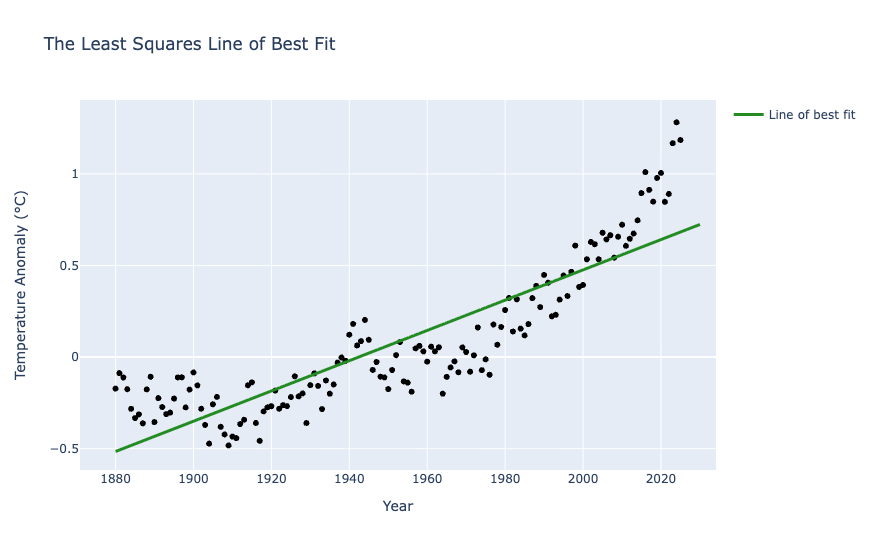

In [49]:
year_grid = pd.DataFrame({"Year": np.arange(1880, 2031)})
year_grid["Prediction"] = lin.predict(year_grid[["Year"]])

fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "The Least Squares Line of Best Fit",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)

fig.add_scatter(x = year_grid["Year"], y = year_grid["Prediction"], mode = "lines",
                name = "Line of best fit", line = dict(color = "forestgreen", width = 3))

fig.data[0].name = "Observed data"
fig.update_layout(showlegend = True)

Well, that's the same line. But why did `scikit-learn` report a different intercept? We address this shortly. But first we end the **create $\rightarrow$ fit $\rightarrow$ predict** recipe and illustrate prediction.

### Making Predictions

As with $k$ nearest neighbours, we use `.predict()` and supply a data frame with the same column name as `X`.

In [20]:
new_data = pd.DataFrame({"Year": [1998, 2030]})
lin.predict(new_data)

array([0.45925534, 0.72364004])

The line predicts an anomaly of about $0.46^\circ$C for 1998 (the actual anomaly was about $0.61^\circ$C), and about $0.72^\circ$C for 2030.

Unlike k-NN, **a line keeps going**, so we can make predictions far beyond the range of the data. But we should be careful about that! We'll return to this shortly.

### Least Absolute Deviations Regression

The `LinearRegression` method in `scikit-learn` estimates the line of best fit using *least squares* (it minimizes the sum of squared residuals). If we instead wanted to find the line of best fit using *least absolute deviations* (minimizing the sum of absolute residuals), we can also use `scikit-learn`. However, this is much less common and so we omit a treatment of it here. You may see this in future courses.

---
---

## Interpreting the Coefficients

One big advantage of a line over k-NN is that the coefficients have **meaning**. They are a compact *summary* of the relationship. Let's interpret what we found:

$$\widehat{\text{anomaly}} = -16.05 + 0.00826 \times \text{Year}$$

### The slope $b_1$

> **For each additional unit of $x$, we expect the predicted response changes by $b_1$ units.**

Always interpret the slope **in the units of the problem**:

* The slope is $0.00826$ **$^\circ$C per year**.
* So for each additional year, the global temperature anomaly is predicted to increase by about $0.008^\circ$C.
* That's about $0.083^\circ$C per *decade* and $0.83^\circ$C per *century*, on average over the 146 years of data.

**Be careful:** this describes how *predictions* change with $x$. It does *not* say that moving $x$ *causes* the change. (Recall the predictive vs. causal distinction!)

### The intercept $b_0$

> **The intercept is the predicted response when $x = 0$.**

Here, $b_0 = -16.05$. So the line predicts that in the year 0, the global temperature anomaly was $-16^\circ$C!

That's confusing... What's happening?

* The year 0 is **nearly 1900 years before** the start of our data. We have no information about what happened then, and the line is **extrapolating**... *wildly*.
* The intercept is only meaningful if $x = 0$ is a meaningful and plausible value *within or near* our data. For raw calendar years, it never is.

### The Fix: Center $x$

**Centering** means *subtracting a reference value from $x$* before fitting the model. This shifts the $x$ scale so that "0" means something meaningful. Let's center `Year` at the average year (1952.5) and refit:

In [56]:
# We created this column earlier: Year minus the average year
temps[["Year", "Year_centered"]].head()

,Year,Year_centered
0,1880,-72.5
1,1881,-71.5
2,1882,-70.5
3,1883,-69.5
4,1884,-68.5


In [57]:
lin_centered = LinearRegression().fit(temps[["Year_centered"]], y)

print("Intercept (b0):", lin_centered.intercept_)
print("Slope (b1):    ", lin_centered.coef_[0])

Intercept (b0): 0.08333333479452053
Slope (b1):     0.008262022036574668


Compare to the uncentered fit:

* The **slope is unchanged**: $0.00826$ $^\circ$C per year.
* The **intercept** is now **$0.083$**. *This* matches what we had before. And it's now interpretable: it's the **predicted anomaly when `Year_centered` is 0, i.e., in an average year (1952.5)**. That's a sensible value: the global average anomaly across the whole record is about $0.08^\circ$C above the 1951-1980 baseline.

**IMPORTANT: Centering does not change the fitted line or its predictions at all.** It only changes the *labelling* of the $x$ axis, and thus what the intercept *means*. We can verify this by centering at several different reference values and comparing:

In [63]:
result = []
for reference, label in [(0, "No centering (year 0)"),
                         (1880, "Start of the record (1880)"),
                         (temps["Year"].mean(), "Middle of the record (1952.5)"),
                         (2000, "Year 2000")]:
    model = LinearRegression().fit(temps[["Year"]] - reference, y)
    prediction_2030 = model.predict(pd.DataFrame({"Year": [2030 - reference]}))[0]
    result.append({"Centered at": label,
                   "Intercept": model.intercept_,
                   "Slope": model.coef_[0],
                   "Prediction for 2030": prediction_2030})

pd.DataFrame(result)

,Centered at,Intercept,Slope,Prediction for 2030
0,No centering (year 0),-16.048265,0.008262,0.72364
1,Start of the record (1880),-0.515663,0.008262,0.72364
2,Middle of the record (1952.5),0.083333,0.008262,0.72364
3,Year 2000,0.475779,0.008262,0.72364


Look carefully at the table:

* The **slope** is the same in every row.
* The **prediction for 2030** is the same in every row.
* Only the **intercept** changes, because the intercept is *the predicted response at the reference value*, and the reference value is different in each row.

**Guidelines for centering:**

* Choose a reference value that is **meaningful** and **within the range of your data**. The average of $x$ is a good default. A natural reference (like "the start of the record" or "the year 2000") can also work well.
* After centering, **interpret the intercept as the predicted response at the reference value.**
* When you make predictions from a model fit to centered data, remember to **center the new $x$ values in exactly the same way**.

> **RECAP: Why we center.** the *slope* has the same meaning either way, but centering makes the *intercept* interpretable. (In later courses you'll learn that it also makes the numerical computations more stable and, for models with several explanatory variables, the coefficients easier to understand.)

---

### ✍️ ACTIVITY: Interpret

Fit the least squares line using `Year` centered at **2000**. Write a sentence that interprets the intercept and a sentence that interprets the slope.

<details>
<summary><b>Show Solution</b></summary>

```python
model_2000 = LinearRegression().fit(temps[["Year"]] - 2000, y)
print(model_2000.intercept_, model_2000.coef_[0])
```

The intercept is about $0.48$: *the line predicts that in the year 2000, the global temperature anomaly was about $0.48^\circ$C above the 1951-1980 average.* The slope is still about $0.0083$: *on average, global temperature anomalies increase by about $0.008^\circ$C per year.*
</details>

---
---

## How Well Does the Line Fit? Look at the Residuals

The line is a simple, interpretable summary, but is it a *good* description of the data? A great way to check is to plot the **residuals** against $x$. 

* We call this an assessment of **goodness-of-fit**. 
* If a line were a perfect description of the *pattern* (with only random noise around it), the residuals would look like a shapeless cloud centred on zero.

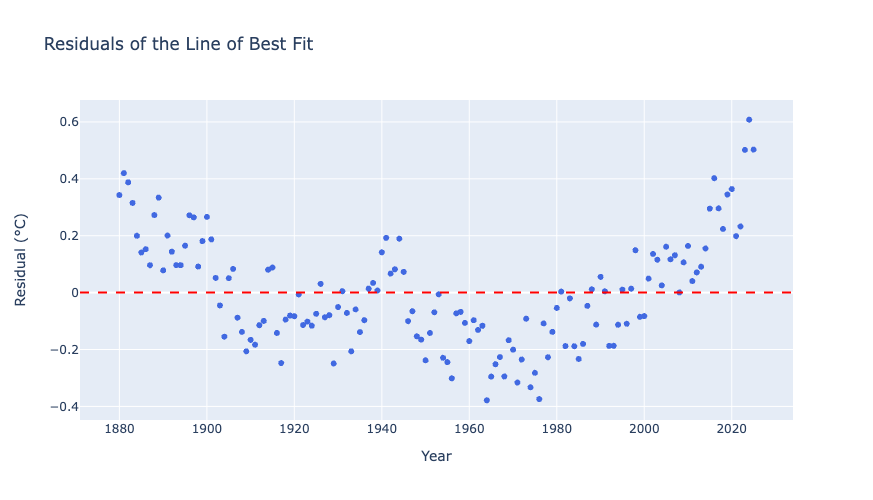

In [54]:
temps["Residual"] = y - lin.predict(X)

fig = px.scatter(temps, x = "Year", y = "Residual",
                 title = "Residuals of the Line of Best Fit",
                 labels = {"Residual": "Residual (°C)"},
                 color_discrete_sequence = ["royalblue"],
                 height = 500)

fig.add_hline(y = 0, line_width = 2, line_dash = "dash", line_color = "red")

The residuals are **not** a shapeless cloud. They have a clear **curved pattern**: mostly positive in the earliest years (the line of best fit was too low), mostly negative through the middle of the record (the line of best fit was too high), and strongly positive in the most recent decades (the line of best fit was too low again).

This is the signature of **a straight line missing a curved pattern**. The warming trend has *accelerated*, and a single straight line can't capture that.

We can also compare the line's performance with k-NN from last lecture:

In [64]:
from sklearn.neighbors import KNeighborsRegressor

print(f"Line of best fit:  SSR = {((y - lin.predict(X)) ** 2).sum()}")

for k in [5, 15, 50, 100]:
    knn = KNeighborsRegressor(n_neighbors = k).fit(X, y)
    residuals = y - knn.predict(X)
    print(f"k-NN with k = {k}: SSR = {(residuals ** 2).sum()}")

Line of best fit:  SSR = 5.44893531947225
k-NN with k = 5: SSR = 0.9253425303071542
k-NN with k = 15: SSR = 1.5125116346030865
k-NN with k = 50: SSR = 4.33041747567888
k-NN with k = 100: SSR = 11.580466048772674


A moderately flexible k-NN model (say $k = 15$) fits the data we have *more closely* than the line does. But the line has big advantages: it's described by just **two numbers**, it's **interpretable** (we can talk about *rate of warming*), and it can **extrapolate**.

**Simple models trade-off predictive accuracy for simplicity and interpretability.** Which is better? That depends on what we want to do with the model, and, as we'll see later in the course, on how well each model predicts *new* data.

---
---

## A Tease: Multiple Linear Regression

Our line used **one** explanatory variable. But we could use **multiple**. A model with two or more explanatory variables, $x_1, x_2, \ldots, x_p$, is called **multiple linear regression**:

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \cdots + b_p x_p$$

For example, we might predict a house's price from its size, age, *and* location. Or, if we had the data, we could predict temperature anomalies from the year *and* the atmospheric CO$_2$ concentration.

Everything we learned here carries over: there's one coefficient per explanatory variable, we determine them by **minimizing the SSR**, and the `scikit-learn` recipe is *identical*. The only change is that `X` has more than one column!

Our temperature data only has one explanatory variable. But we can *create* a second one from it. Remember that the residuals showed a *curved* pattern. A natural way to capture curvature is to add the **square** of $x$ (in this case, centered year) as a second explanatory variable:

In [65]:
temps["Year_centered_sq"] = temps["Year_centered"] ** 2

X2 = temps[["Year_centered", "Year_centered_sq"]]      # two explanatory variables!

multi = LinearRegression().fit(X2, y)

print("Intercept:", multi.intercept_)
print("Coefficients (Year_centered, Year_centered_sq):", multi.coef_)

Intercept: -0.08595225573811398
Coefficients (Year_centered, Year_centered_sq): [8.26202204e-03 9.53050474e-05]


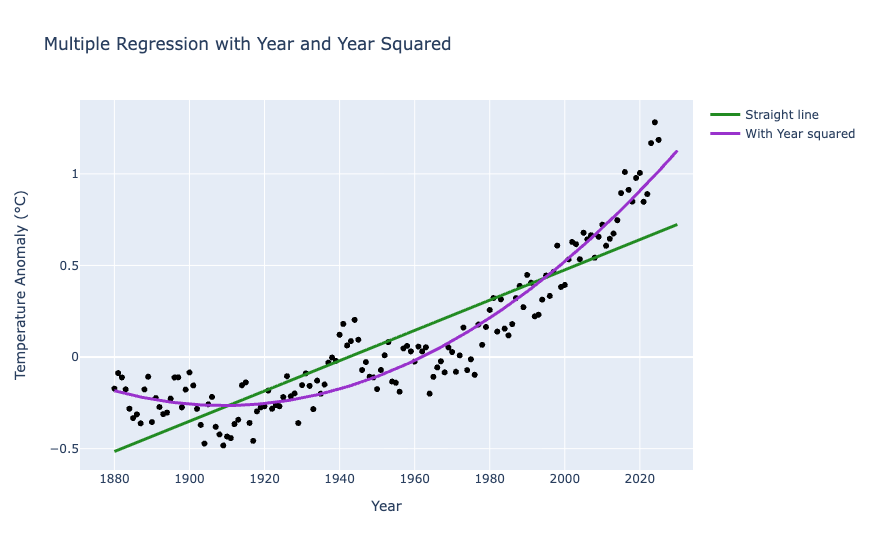

In [71]:
# Predictions on a grid (remember to center and square the new years in the same way!)
grid = pd.DataFrame({"Year": np.arange(1880, 2031)})
grid["Year_centered"] = grid["Year"] - temps["Year"].mean()
grid["Year_centered_sq"] = grid["Year_centered"] ** 2
grid["Prediction"] = multi.predict(grid[["Year_centered", "Year_centered_sq"]])

fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Multiple Regression with Year and Year Squared",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)

fig.add_scatter(x = year_grid["Year"], y = year_grid["Prediction"], mode = "lines", name = "Straight line",
                line = dict(color = "forestgreen", width = 3))
fig.add_scatter(x = grid["Year"], y = grid["Prediction"], mode = "lines", name = "With Year squared",
                line = dict(color = "darkorchid", width = 3))

fig.update_layout(showlegend = True)

In [72]:
print(f"SSR, straight line:       {((y - lin.predict(X)) ** 2).sum()}")
print(f"SSR, with Year squared:   {((y - multi.predict(X2)) ** 2).sum()}")
print(f"2030 prediction, straight line:     {lin.predict(pd.DataFrame({'Year': [2030]}))[0]}")
print(f"2030 prediction, with Year squared: {multi.predict(pd.DataFrame({'Year_centered': [2030 - temps['Year'].mean()], 'Year_centered_sq': [(2030 - temps['Year'].mean()) ** 2]}))[0]}")

SSR, straight line:       5.44893531947225
SSR, with Year squared:   2.1021974418728155
2030 prediction, straight line:     0.7236400426290572
2030 prediction, with Year squared: 1.1267803933415381


Adding just one extra explanatory variable **more than halved the SSR**, and the curve follows the accelerating warming much better. Its 2030 prediction is also far closer to recent anomalies.

(You might wonder why this is still called *linear* regression when the fitted curve isn't a straight line. The word "linear" refers to the way the *coefficients* enter the model: each is simply multiplied by a variable and added up. The *fitted curve* can bend.)

**But this raises an important question.** If adding $x^2$ helped, why not add $x^3$, $x^4$, ..., $x^{20}$? Each additional term lets the curve bend more and hug the data more closely, driving the SSR lower and lower. At some point we'd have a wiggly curve that chases the noise, just like k-NN with $k = 1$. **How complex should the model be?** That's one of the central questions of predictive modeling, and we'll answer it later in the course.

---

> **Not covered here:** how *certain* are we about the line? Confidence intervals for the line of best fit, and hypothesis tests for the coefficients (e.g., *is the slope really different from zero?*), build directly on the confidence interval and hypothesis testing lectures. We will explore this in a tutorial.

---
---

## Summary of Useful Methods and Functions

| Code | What it does |
|---|---|
| `from sklearn.linear_model import LinearRegression` | Imports the least squares linear regression method. |
| `model = LinearRegression()` | **Creates** a linear regression model. |
| `model.fit(X, y)` | **Fits** the model: finds the coefficients that minimize the SSR. `X` may have one or more columns. |
| `model.intercept_` | The fitted intercept $b_0$. |
| `model.coef_` | The fitted slope(s) $b_1, b_2, \ldots$ (an array with one entry per column of `X`). |
| `model.predict(new_X)` | **Predicts** the response for each row of `new_X`. |
| `df["x"] - reference` | **Centers** `x` at a chosen reference value. |

---
---

## Key Takeaways

* **Simple linear regression** predicts a numeric response with a straight line $\hat{y} = b_0 + b_1 x$ that depends on a *single* explanatory variable. The numbers $b_0$ (intercept) and $b_1$ (slope) are the model's **coefficients**.
* There are infinitely many possible lines. The **line of best fit** is the one with the smallest **loss**, as measured by an **objective function**.
* **Estimation by optimization** is a central idea in machine learning: choose a *loss function*, then find the parameter values that *minimize* it. This is the same approach for many methods, not just lines.
    * **Least squares** minimizes the sum of squared residuals (SSR) and is the default.
    * **Least absolute error** minimizes the sum of absolute residuals (SAR).
* **Interpret** the slope as *the change in predicted response expected for a one-unit increase in $x$* (in the units of the problem), and the intercept as *the predicted response when $x = 0$*.
* The intercept is only meaningful if $x = 0$ is sensible. **Centering** $x$ at a meaningful reference value fixes this. It changes the intercept's meaning, but not the slope, the fitted line, or any predictions.
* **Residual plots** reveal what a model misses: a curved pattern means a straight line isn't capturing everything.
* **Multiple linear regression** uses *several* explanatory variables, $\hat{y} = b_0 + b_1 x_1 + \cdots + b_p x_p$, with the same recipe in `scikit-learn`. The more terms we use in the model, the better the model will fit the data. But **how complex should a model be?** That's a topic we'll revisit in a future lecture.

---
---